# EDA: characterise the Corpus

Exploratory data analysis of the SEC EDGAR Corpus supplied with the assessment.
Every analysis loads Filings through the `edgar_rag` Corpus seam, the same code the
indexer and API will use, and ends with a **so the design does X** conclusion.
Findings are collected in [`docs/findings.md`](../../docs/findings.md).

This file is the source of truth (jupytext percent format). The paired `.ipynb`
is generated with `make eda` and is never edited by hand.

In [1]:
from collections import Counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.colors import ListedColormap
from matplotlib.patches import Patch

from edgar_rag.corpus import load_corpus

filings = load_corpus()
print(f"{len(filings)} Filings from {len({f.ticker for f in filings})} Companies")

246 Filings from 54 Companies


## 1. Inventory and coverage

How many Filings does each Company have, of which Form Type, and in which Calendar
Quarters? Calendar Quarter is taken from the header as written. Filings whose header
has no Calendar Quarter are counted in a separate column; deriving their Report
Period is a later analysis.

In [2]:
df = pd.DataFrame(
    {
        "ticker": f.ticker,
        "company": f.company,
        "form_type": f.form_type,
        "calendar_quarter": f.calendar_quarter,
        "report_period": f.report_period,
        "filing_date": f.filing_date,
    }
    for f in filings
)

per_company = (
    df.pivot_table(index="ticker", columns="form_type", values="company", aggfunc="count")
    .fillna(0)
    .astype(int)
)
per_company["total"] = per_company.sum(axis=1)
per_company = per_company.sort_values(["total", "10-Q"], ascending=False)
per_company.T

ticker,DIS,JNJ,AAPL,AMZN,MSFT,NVDA,TSLA,XOM,KO,PFE,...,PG,RTX,SBUX,T,TGT,TMO,UPS,V,VZ,WMT
form_type,,,,,,,,,,,,,,,,,,,,,
10-K,4,5,4,4,4,4,4,4,3,3,...,1,1,1,1,1,1,1,1,1,1
10-Q,13,12,12,12,12,12,12,12,12,12,...,0,0,0,0,0,0,0,0,0,0
total,17,17,16,16,16,16,16,16,15,15,...,1,1,1,1,1,1,1,1,1,1


In [3]:
filings_per_company = Counter(per_company["total"])
pd.DataFrame(
    sorted(filings_per_company.items(), reverse=True),
    columns=["Filings per Company", "Companies"],
).set_index("Filings per Company").T

Filings per Company,17,16,15,14,8,4,2,1
Companies,2,6,3,1,1,2,2,37


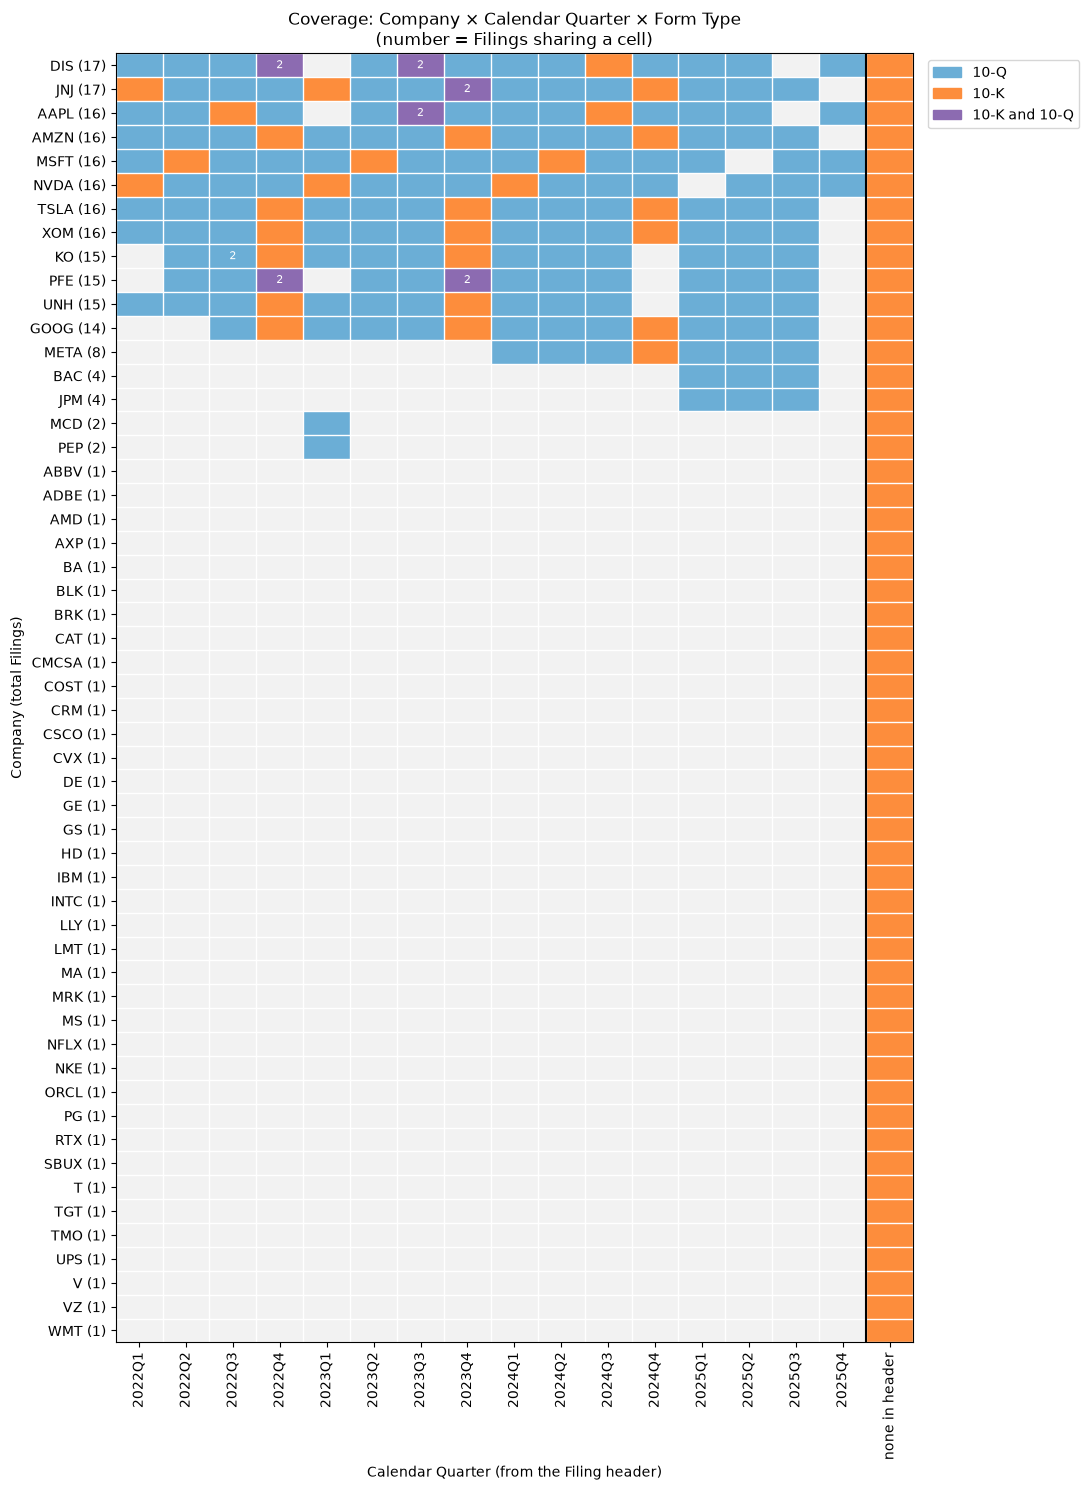

In [4]:
NO_QUARTER = "none in header"

known_quarters = df["calendar_quarter"].dropna()
quarters = [str(q) for q in pd.period_range(known_quarters.min(), known_quarters.max(), freq="Q")]
columns = quarters + [NO_QUARTER]
tickers = list(per_company.index)

# Cell code: 0 = no Filing, 1 = 10-Q only, 2 = 10-K only, 3 = both.
codes = np.zeros((len(tickers), len(columns)), dtype=int)
counts = np.zeros_like(codes)
for f in filings:
    row = tickers.index(f.ticker)
    col = columns.index(f.calendar_quarter or NO_QUARTER)
    codes[row, col] |= 2 if f.form_type == "10-K" else 1
    counts[row, col] += 1

colours = ["#f2f2f2", "#6baed6", "#fd8d3c", "#8c6bb1"]
fig, ax = plt.subplots(figsize=(11, 15))
ax.imshow(codes, cmap=ListedColormap(colours), vmin=0, vmax=3, aspect="auto")
for r, c in zip(*np.nonzero(counts > 1), strict=True):
    ax.text(c, r, counts[r, c], ha="center", va="center", fontsize=8, color="white")

ax.set_xticks(range(len(columns)), columns, rotation=90)
ax.set_yticks(range(len(tickers)), [f"{t} ({per_company.loc[t, 'total']})" for t in tickers])
ax.set_xticks(np.arange(-0.5, len(columns)), minor=True)
ax.set_yticks(np.arange(-0.5, len(tickers)), minor=True)
ax.grid(which="minor", color="white", linewidth=1)
ax.tick_params(which="minor", length=0)
ax.axvline(len(quarters) - 0.5, color="black", linewidth=1.5)
ax.set_xlabel("Calendar Quarter (from the Filing header)")
ax.set_ylabel("Company (total Filings)")
ax.set_title("Coverage: Company × Calendar Quarter × Form Type\n(number = Filings sharing a cell)")
ax.legend(
    handles=[
        Patch(color=colour, label=label)
        for colour, label in zip(colours[1:], ["10-Q", "10-K", "10-K and 10-Q"], strict=True)
    ],
    loc="upper left",
    bbox_to_anchor=(1.01, 1.0),
)
fig.tight_layout()
plt.show()

In [5]:
missing_quarter = df[df["calendar_quarter"].isna()]
shared_cells = int((counts[:, : len(quarters)] > 1).sum())
print(f"Filings with no Calendar Quarter in the header: {len(missing_quarter)}")
print(f"Companies with exactly one Filing: {(per_company['total'] == 1).sum()}")
print(f"Companies with 4 or more Filings: {(per_company['total'] >= 4).sum()}")
print(f"Company × Calendar Quarter cells holding more than one Filing: {shared_cells}")

Filings with no Calendar Quarter in the header: 54
Companies with exactly one Filing: 37
Companies with 4 or more Filings: 15
Company × Calendar Quarter cells holding more than one Filing: 7


**What the grid shows**

- Coverage is very uneven. 12 Companies have 14–17 Filings spread over 2022Q1–2025Q4,
  META has 8, JPM and BAC have 4, MCD and PEP have 2, and the remaining 37 Companies
  have a single 10-K.
- Every Company has exactly one Filing with no Calendar Quarter (or Report Period) in
  its header: its most recent 10-K (filed between 2024 and 2026, plus GE's from 2015).
  For the 37 single-Filing Companies that is their only Filing, so they cannot be
  placed on the time axis from the header alone.
- Several Company × Calendar Quarter cells hold two Filings (e.g. Coca-Cola's two
  2022Q3 Filings), so Calendar Quarter cannot be a unique key.
- Coverage starts in 2022Q1, a year before the brief's "2023–2025".

**So the design does:**

- Treat Company coverage as first-class metadata: classify each Company as a Tracked
  Company (quarterly Filings across years, trend questions answerable) or a Snapshot
  Company (point-in-time only), and have the Answer Call state plainly when coverage
  limits an answer.
- Filter retrieval on Company and Report Period metadata instead of relying on
  similarity alone, so a trend question about a Tracked Company is not crowded out by
  one-off 10-Ks, and a comparison across Snapshot Companies retrieves each of them.
- Derive a Report Period for every Filing whose header lacks one (next analysis), and
  never use Calendar Quarter as a key.